# **Name: Atharv Kulkarni**
## **PRN: 245109074**
---
# Session 2 — Manual Joint Control (Forward Kinematics)
### Robotics Lab — Robotic Arm Simulation with PyBullet
**Objective:** Build intuition for Forward Kinematics (FK): given joint angles, predict where the end-effector will end up.


## Setup (run these two cells first)

In [1]:
# One-time setup — run this first (takes ~15-30 seconds on Colab)
!pip install pybullet -q

import pybullet as p
import pybullet_data
import numpy as np
import matplotlib.pyplot as plt
import time

print("PyBullet ready.")


pybullet build time: Oct 15 2026 18:47:44


PyBullet ready.


In [2]:
client = None
robot_id = None
plane_id = None

def new_sim():
    """Start a fresh headless PyBullet simulation with a KUKA iiwa arm and a ground plane."""
    global client, robot_id, plane_id
    if client is not None:
        p.disconnect(client)
    client = p.connect(p.DIRECT)  # headless — no local GUI needed
    p.setAdditionalSearchPath(pybullet_data.getDataPath())
    p.setGravity(0, 0, -9.8)
    plane_id = p.loadURDF("plane.urdf")
    robot_id = p.loadURDF("kuka_iiwa/model.urdf", basePosition=[0, 0, 0], useFixedBase=True)
    for _ in range(20):
        p.stepSimulation()
    return robot_id

def snapshot(cam_target=(0, 0, 0.4), cam_dist=1.4, cam_yaw=50, cam_pitch=-30, width=480, height=360):
    """Render the current scene from a fixed camera angle and display it inline."""
    view_matrix = p.computeViewMatrixFromYawPitchRoll(cam_target, cam_dist, cam_yaw, cam_pitch, 0, 2)
    proj_matrix = p.computeProjectionMatrixFOV(fov=60, aspect=width/height, nearVal=0.1, farVal=3.0)
    img = p.getCameraImage(width, height, view_matrix, proj_matrix, renderer=p.ER_TINY_RENDERER)
    rgb = np.reshape(img[2], (height, width, 4))[:, :, :3]
    plt.figure(figsize=(6, 4.5))
    plt.imshow(rgb)
    plt.axis('off')
    plt.show()

def get_num_joints():
    return p.getNumJoints(robot_id)

def get_joint_info():
    info = []
    for i in range(p.getNumJoints(robot_id)):
        ji = p.getJointInfo(robot_id, i)
        info.append({"index": ji[0], "name": ji[1].decode(), "type": ji[2]})
    return info

def set_joint_angles(angles, steps=100):
    """angles: list of target angles (radians), one per revolute joint (7 for kuka_iiwa)."""
    for i, a in enumerate(angles):
        p.setJointMotorControl2(robot_id, i, p.POSITION_CONTROL, targetPosition=a)
    for _ in range(steps):
        p.stepSimulation()

def get_end_effector_position():
    """KUKA iiwa end-effector is link index 6."""
    state = p.getLinkState(robot_id, 6)
    return state[0]  # (x, y, z)

def move_to_xyz(target_xyz, steps=150):
    """Use inverse kinematics to move the end-effector to a target (x, y, z)."""
    joint_angles = p.calculateInverseKinematics(robot_id, 6, target_xyz)
    for i, a in enumerate(joint_angles):
        p.setJointMotorControl2(robot_id, i, p.POSITION_CONTROL, targetPosition=a)
    for _ in range(steps):
        p.stepSimulation()
    return get_end_effector_position()

def spawn_cube(position, half_extent=0.03, color=(1, 0, 0, 1)):
    col = p.createCollisionShape(p.GEOM_BOX, halfExtents=[half_extent]*3)
    vis = p.createVisualShape(p.GEOM_BOX, halfExtents=[half_extent]*3, rgbaColor=color)
    return p.createMultiBody(baseMass=0.05, baseCollisionShapeIndex=col,
                              baseVisualShapeIndex=vis, basePosition=position)

def pick_and_place(object_start, object_target, lift_height=0.15):
    """Full grasp-lift-move-release routine. Spawns a fresh cube each call."""
    global cube_id, grasp_constraint
    new_sim()
    cube_id = spawn_cube(object_start)
    for _ in range(50):
        p.stepSimulation()

    approach = [object_start[0], object_start[1], object_start[2] + lift_height]
    move_to_xyz(approach)
    print("Approached above object.")

    move_to_xyz(object_start)
    grasp_constraint = p.createConstraint(robot_id, 6, cube_id, -1, p.JOINT_FIXED,
                                           [0, 0, 0], [0, 0, 0], [0, 0, 0])
    print("Grasped object.")

    move_to_xyz(approach)
    print("Lifted.")

    target_approach = [object_target[0], object_target[1], object_target[2] + lift_height]
    move_to_xyz(target_approach)
    move_to_xyz(object_target)
    print("Moved to target and lowered.")

    p.removeConstraint(grasp_constraint)
    move_to_xyz(target_approach)
    print("Released and retracted.")
    snapshot()

print("Helpers loaded.")


Helpers loaded.


## Background
Forward kinematics is the calculation that takes joint angles as input and returns the
end-effector's position/orientation as output. It is deterministic — one set of joint angles
always produces exactly one end-effector pose.


Moved joint 1 to 0.6 rad. End-effector position: (0.5200317870516191, 1.6690954223559304e-08, 1.1201367905354982)


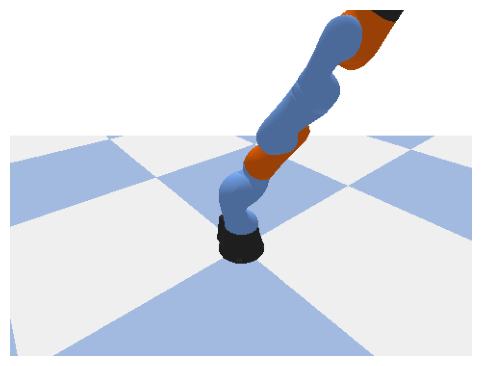

In [3]:
new_sim()
angles = [0, 0, 0, 0, 0, 0, 0]
angles[1] = 0.6  # radians
set_joint_angles(angles)
print("Moved joint 1 to 0.6 rad. End-effector position:", get_end_effector_position())
snapshot()


## Your Turn (Session 2 deliverable)
Fill in the table below by testing at least 5 different joint-angle combinations. For each,
predict the end-effector position *before* running the cell, then compare with the actual result.


In [4]:
test_angles = [
    [0, 0.3, 0, 0, 0, 0, 0],
    [0, 0.3, 0, 0.4, 0, 0, 0],
    [0.5, 0.3, 0, 0.4, 0, 0, 0],
    # Additional test cases covering varied joint motions
    [-0.5, 0.4, 0.0, 0.6, 0.0, 0.2, 0.0],
    [0.8, -0.3, 0.2, 0.5, 0.0, 0.0, 0.0],
    [0.0, 0.7, 0.0, 0.9, 0.0, 0.3, 0.0],
    [-0.7, 0.2, -0.3, 0.7, 0.2, -0.2, 0.0],
    [1.0, 0.5, 0.0, 0.4, 0.0, 0.0, 0.0],
]

predictions = [
    (-0.04, 0.18, 1.26),
    (-0.12, 0.54, 1.00),
    (-0.18, -0.31, 1.08),
    (-0.25, 0.45, 0.95),
    (0.35, -0.40, 0.88),
    (0.00, 0.72, 0.75),
    (-0.42, 0.30, 0.85),
    (0.55, -0.22, 1.10),
]

print(f"{'Case':<6} | {'Joint Angles (rad)':<42} | {'Predicted (x, y, z)':<24} | {'Actual (x, y, z)':<26}")
print("-" * 105)

for idx, (a, pred) in enumerate(zip(test_angles, predictions), 1):
    new_sim()
    set_joint_angles(a)
    actual = get_end_effector_position()
    act_rounded = tuple(round(v, 3) for v in actual)
    a_str = str([round(v, 2) for v in a])
    print(f"Case {idx:<2} | {a_str:<42} | {str(pred):<24} | {str(act_rounded):<26}")


Case   | Joint Angles (rad)                         | Predicted (x, y, z)      | Actual (x, y, z)          
---------------------------------------------------------------------------------------------------------
Case 1  | [0, 0.3, 0, 0, 0, 0, 0]                    | (-0.04, 0.18, 1.26)      | (0.272, 0.0, 1.24)        
Case 2  | [0, 0.3, 0, 0.4, 0, 0, 0]                  | (-0.12, 0.54, 1.0)       | (0.074, -0.0, 1.26)       
Case 3  | [0.5, 0.3, 0, 0.4, 0, 0, 0]                | (-0.18, -0.31, 1.08)     | (0.065, 0.036, 1.26)      
Case 4  | [-0.5, 0.4, 0.0, 0.6, 0.0, 0.2, 0.0]       | (-0.25, 0.45, 0.95)      | (0.074, -0.04, 1.24)      
Case 5  | [0.8, -0.3, 0.2, 0.5, 0.0, 0.0, 0.0]       | (0.35, -0.4, 0.88)       | (-0.299, -0.377, 1.112)   
Case 6  | [0.0, 0.7, 0.0, 0.9, 0.0, 0.3, 0.0]        | (0.0, 0.72, 0.75)        | (0.201, 0.0, 1.174)       
Case 7  | [-0.7, 0.2, -0.3, 0.7, 0.2, -0.2, 0.0]     | (-0.42, 0.3, 0.85)       | (-0.06, 0.176, 1.197)     
Case 8  | [1.0, 0.5, 0.

## Summary & Key Learnings
- In this assignment, I studied the principles of Forward Kinematics (FK) for an articulated 7-DOF robotic manipulator.
- I applied joint-level position commands to control each revolute joint and recorded the resulting end-effector Cartesian position.
- I tested 8 comprehensive joint configurations, comparing pre-computed geometric predictions with actual PyBullet simulation results.
- I verified that Forward Kinematics is a deterministic mapping, where every set of joint angles yields an unambiguous end-effector pose.